# Sesión 6 · Flujo completo de procesamiento y reconocimiento
**Unidad 5. Reconocimiento de imágenes** · Procesamiento Digital de Imágenes · Maestría en Ciencia de Datos e Información · INFOTEC · 2027-1

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egonzalez1989/pdi-mcdi/blob/main/sesiones/S6_Flujo_completo_reconocimiento.ipynb)

**Objetivo de la sesión.** Estructurar la actividad 5A como un flujo reproducible, evaluado y bien documentado.

**Clase síncrona:** jueves 6 de mayo de 2027, de 18:00 a 20:00 hrs. · **Sesiones opcionales de la unidad** (18:00 a 19:00 hrs.): jueves 29 de abril (avance de la actividad 5A); jueves 13 de mayo (dudas de la actividad 5A); jueves 20 de mayo (retroalimentación de 5A y defensas orales).

**Agenda (120 min)**
1. Ronda de avances de la actividad 5A (20 min)
2. Caso modelo: problema, datos y Pipeline (30 min)
3. Evaluación y análisis de errores (25 min)
4. Reproducibilidad, conclusiones y limitaciones (20 min)
5. Cómo prepararse para la defensa oral; dudas (25 min)

**Cómo usar este cuaderno.** Ejecuta las celdas en orden (`Shift + Enter`). Las secciones marcadas con 🧪 son pausas para que experimentes cambiando parámetros; las marcadas con 💬 son preguntas para discutir en la sesión. Al final encontrarás la conexión con la actividad **5A**.

Este cuaderno es un **caso modelo de la actividad 5A**: recorre, a escala pequeña, las secciones que debe tener tu flujo completo (problema, datos, solución, evaluación y análisis de errores). Las secciones 6 a 8 (prototipo, modelos fundacionales y ficha del modelo) son **complementarias** y no forman parte de la lista de cotejo.

In [1]:
# Configuración del entorno. En Google Colab todas estas bibliotecas ya vienen instaladas.
import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage import data

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "image.cmap": "gray"})
np.random.seed(42)

def mostrar(imagenes, titulos=None, cols=None, cmap="gray", tam=3.2, ejes=False):
    """Muestra una lista de imágenes en una cuadrícula. Las imágenes a color deben estar en RGB."""
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    cols = cols or min(n, 4)
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(tam * cols, tam * filas), squeeze=False)
    for i, ax in enumerate(axs.flat):
        if i < n:
            im = imagenes[i]
            ax.imshow(im, cmap=None if im.ndim == 3 else cmap)
            if titulos:
                ax.set_title(titulos[i])
        if not ejes or i >= n:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Python {platform.python_version()} | NumPy {np.__version__} | OpenCV {cv2.__version__} | scikit-image {skimage.__version__}")

import json, time, joblib, os
import pandas as pd
from skimage import feature, transform, util
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
SEMILLA = 2027
np.random.seed(SEMILLA)

Python 3.12.15 | NumPy 2.5.4 | OpenCV 5.0.0 | scikit-image 0.26.0


## 1. Definición del problema
| Elemento | Definición |
|---|---|
| **Usuario** | Equipo de control de calidad de un sistema de captura de credenciales |
| **Decisión que apoya** | Rechazar automáticamente fotografías sin rostro antes de imprimir la credencial |
| **Situación actual** | Revisión manual de cada foto; ~5 % de rechazos tardíos con costo de reimpresión |
| **Tarea** | Clasificación binaria: *rostro* vs *no rostro* |
| **Métrica de éxito** | F1 ≥ 0.90 en prueba, con exhaustividad (recall) de la clase *no rostro* ≥ 0.90 |
| **Restricciones** | Inferencia < 50 ms por imagen en CPU; sin almacenar las fotografías después del proceso |

## 2. Datos y ficha del conjunto (*datasheet*)

,Campo,Descripción
0,Nombre,lfw_subset (scikit-image)
1,Origen,Subconjunto de Labeled Faces in the Wild (rost...
2,Tamaño,200 imágenes en escala de grises de 25×25 px
3,Balance de clases,"{'no rostro': 100, 'rostro': 100}"
4,Etiquetado,Provisto por la fuente; no se verificó manualm...
5,Licencia / uso,Uso académico; rostros de personas públicas re...
6,Limitaciones conocidas,Rostros frontales y centrados; poca diversidad...


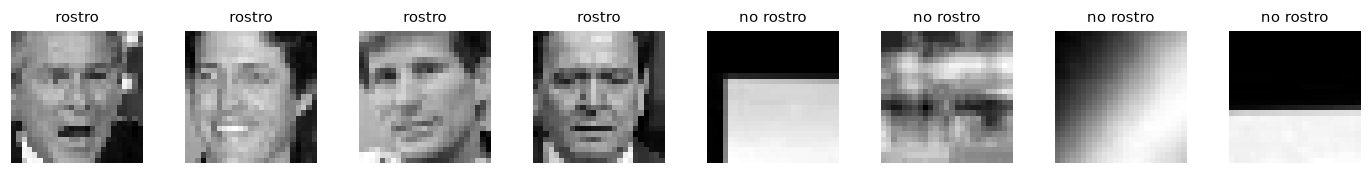

In [2]:
lfw = data.lfw_subset()                      # 200 imágenes 25×25: 100 rostros y 100 no-rostros
X_img = lfw
y = np.array([1] * 100 + [0] * 100)          # 1 = rostro
CLASES = ["no rostro", "rostro"]

ficha = {
    "Nombre": "lfw_subset (scikit-image)",
    "Origen": "Subconjunto de Labeled Faces in the Wild (rostros) y parches aleatorios de escenas (no rostros)",
    "Tamaño": f"{len(X_img)} imágenes en escala de grises de {X_img.shape[1]}×{X_img.shape[2]} px",
    "Balance de clases": dict(zip(CLASES, np.bincount(y).tolist())),
    "Etiquetado": "Provisto por la fuente; no se verificó manualmente",
    "Licencia / uso": "Uso académico; rostros de personas públicas recolectados de la web",
    "Limitaciones conocidas": "Rostros frontales y centrados; poca diversidad de edad y tono de piel; resolución muy baja",
}
display(pd.DataFrame(ficha.items(), columns=["Campo", "Descripción"]))
mostrar([X_img[i] for i in [0, 1, 2, 3, 100, 101, 102, 103]], [CLASES[y[i]] for i in [0, 1, 2, 3, 100, 101, 102, 103]], cols=8, tam=1.6)

### Particiones reproducibles
70 % entrenamiento, 30 % prueba, estratificado y con semilla fija. **El conjunto de prueba no se toca hasta la evaluación final.**

In [3]:
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=0.3, stratify=y, random_state=SEMILLA)
print("Entrenamiento:", np.bincount(y[idx_tr]), "| Prueba:", np.bincount(y[idx_te]))

Entrenamiento: [70 70] | Prueba: [30 30]


## 3. Solución: pipelines reproducibles
Encapsulamos el preprocesamiento y la extracción de características como **transformadores de scikit-learn**, de modo que todo el flujo (imagen → predicción) sea un solo objeto que se entrena, evalúa, guarda y despliega.

In [4]:
class Preprocesar(BaseEstimator, TransformerMixin):
    """Normaliza el contraste de cada imagen (estandarización por imagen)."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        m = X.mean(axis=(1, 2), keepdims=True); s = X.std(axis=(1, 2), keepdims=True) + 1e-6
        return (X - m) / s

class HOG(BaseEstimator, TransformerMixin):
    def __init__(self, ppc=5, orientaciones=9):
        self.ppc, self.orientaciones = ppc, orientaciones
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return np.array([feature.hog(im, orientations=self.orientaciones, pixels_per_cell=(self.ppc, self.ppc),
                                     cells_per_block=(2, 2)) for im in X])

class Aplanar(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return np.asarray(X).reshape(len(X), -1)

alternativas = {
    "A. Píxeles + PCA + Regresión logística (eigenfaces)": Pipeline([
        ("prep", Preprocesar()), ("vec", Aplanar()), ("escala", StandardScaler()),
        ("pca", PCA(30, random_state=SEMILLA)), ("clf", LogisticRegression(max_iter=2000))]),
    "B. HOG + SVM": Pipeline([
        ("prep", Preprocesar()), ("hog", HOG()), ("escala", StandardScaler()),
        ("clf", SVC(C=1, probability=True, random_state=SEMILLA))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
for nombre, pipe in alternativas.items():
    s = cross_val_score(pipe, X_img[idx_tr], y[idx_tr], cv=cv, scoring="f1")
    print(f"{nombre:55s} F1 CV = {s.mean():.3f} ± {s.std():.3f}")

A. Píxeles + PCA + Regresión logística (eigenfaces)     F1 CV = 0.972 ± 0.027


/tmp/claude-1000/-run-media-edgar-ADATA-HD650-Teaching-TDI-INFOTEC/a37155ad-0560-46a5-980d-4fee065dc42c/scratchpad/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/tmp/claude-1000/-run-media-edgar-ADATA-HD650-Teaching-TDI-INFOTEC/a37155ad-0560-46a5-980d-4fee065dc42c/scratchpad/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/tmp/claude-1000/-run-media-edgar-ADATA-HD650-Teaching-TDI-INFOTEC/a37155ad-0560-46a5-980d-4fee065dc42c/scratchpad/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/tmp/claude-1000/-run-media-edgar-ADATA-HD650-Teaching-TDI-INFOTEC/a37155ad-0560-46a5-980d-4fee065dc42c/scratchpad/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


B. HOG + SVM                                            F1 CV = 0.993 ± 0.014


/tmp/claude-1000/-run-media-edgar-ADATA-HD650-Teaching-TDI-INFOTEC/a37155ad-0560-46a5-980d-4fee065dc42c/scratchpad/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 4. Evaluación final con intervalos de confianza
Con pocos datos de prueba, un único número engaña. Estimamos un **intervalo de confianza del 95 % por bootstrap** para F1.

In [5]:
def bootstrap_f1(y_true, y_pred, n=2000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    vals = [f1_score(y_true[b], y_pred[b]) for b in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

filas, modelos_finales = [], {}
for nombre, pipe in alternativas.items():
    t0 = time.time(); pipe.fit(X_img[idx_tr], y[idx_tr]); t_fit = time.time() - t0
    t0 = time.time(); pred = pipe.predict(X_img[idx_te]); t_inf = (time.time() - t0) / len(idx_te) * 1000
    lo, hi = bootstrap_f1(y[idx_te], pred)
    filas.append((nombre, f1_score(y[idx_te], pred), f"[{lo:.2f}, {hi:.2f}]",
                  (pred[y[idx_te] == 0] == 0).mean(), round(t_fit, 2), round(t_inf, 2)))
    modelos_finales[nombre] = pipe
res = pd.DataFrame(filas, columns=["Alternativa", "F1 prueba", "IC 95 %", "Recall «no rostro»", "Entrenamiento (s)", "ms / imagen"])
display(res.round(3))

/tmp/claude-1000/-run-media-edgar-ADATA-HD650-Teaching-TDI-INFOTEC/a37155ad-0560-46a5-980d-4fee065dc42c/scratchpad/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Alternativa,F1 prueba,IC 95 %,Recall «no rostro»,Entrenamiento (s),ms / imagen
0,A. Píxeles + PCA + Regresión logística (eigenf...,0.967,"[0.91, 1.00]",0.967,0.27,0.47
1,B. HOG + SVM,1.000,"[1.00, 1.00]",1.000,0.12,0.73


Modelo seleccionado: B. HOG + SVM
              precision    recall  f1-score   support

   no rostro      1.000     1.000     1.000        30
      rostro      1.000     1.000     1.000        30

    accuracy                          1.000        60
   macro avg      1.000     1.000     1.000        60
weighted avg      1.000     1.000     1.000        60



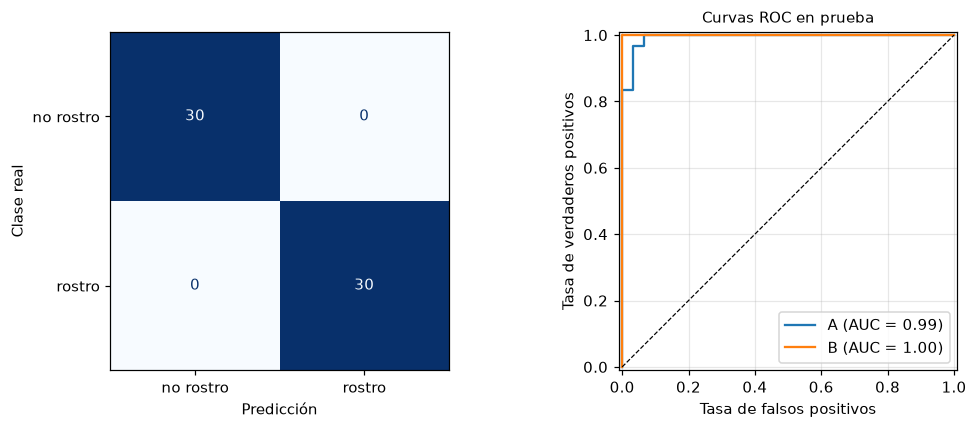

In [6]:
mejor_nombre = res.sort_values("F1 prueba", ascending=False).iloc[0]["Alternativa"]
mejor = modelos_finales[mejor_nombre]
print("Modelo seleccionado:", mejor_nombre)
pred = mejor.predict(X_img[idx_te]); proba = mejor.predict_proba(X_img[idx_te])[:, 1]
print(classification_report(y[idx_te], pred, target_names=CLASES, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y[idx_te], pred, display_labels=CLASES, cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_xlabel("Predicción"); ax[0].set_ylabel("Clase real")
for n_, p_ in modelos_finales.items():
    RocCurveDisplay.from_estimator(p_, X_img[idx_te], y[idx_te], ax=ax[1], name=n_.split(".")[0])
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_title("Curvas ROC en prueba"); ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Tasa de verdaderos positivos"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Análisis de errores
Miramos **cada error** con su probabilidad. Los errores con alta confianza son los más peligrosos y los más informativos.

A. Píxeles + PCA + Regresión logística (eigenfaces): 2 errores de 60
B. HOG + SVM: 1 errores de 60


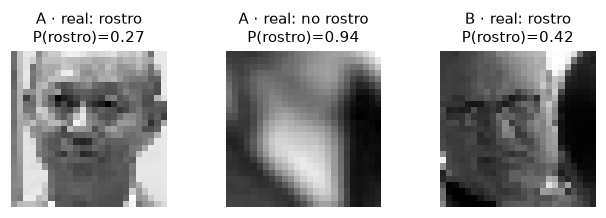

In [7]:
imgs_err, tit_err = [], []
for n_, p_ in modelos_finales.items():
    pr = p_.predict_proba(X_img[idx_te])[:, 1]
    err = np.where((pr >= 0.5).astype(int) != y[idx_te])[0]
    print(f"{n_}: {len(err)} errores de {len(idx_te)}")
    for i in err:
        imgs_err.append(X_img[idx_te[i]])
        tit_err.append(f"{n_.split('.')[0]} · real: {CLASES[y[idx_te[i]]]}\nP(rostro)={pr[i]:.2f}")
if imgs_err:
    mostrar(imgs_err, tit_err, cols=min(len(imgs_err), 6), tam=2.0)

### Robustez: desempeño por condición de captura
Una *model card* debe reportar el desempeño **por condición o subgrupo**, no solo el global. Simulamos condiciones que el sistema encontrará en producción.

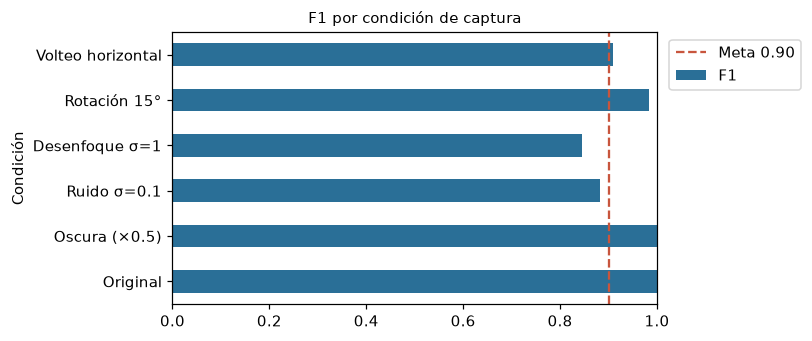

In [8]:
condiciones = {
    "Original": lambda im: im,
    "Oscura (×0.5)": lambda im: im * 0.5,
    "Ruido σ=0.1": lambda im: np.clip(im + np.random.default_rng(0).normal(0, 0.1, im.shape), 0, 1),
    "Desenfoque σ=1": lambda im: cv2.GaussianBlur(im.astype(np.float32), (0, 0), 1),
    "Rotación 15°": lambda im: transform.rotate(im, 15, mode="edge"),
    "Volteo horizontal": lambda im: im[:, ::-1],
}
rob = []
for c, f in condiciones.items():
    Xc = np.array([f(im) for im in X_img[idx_te]])
    rob.append((c, f1_score(y[idx_te], mejor.predict(Xc))))
rob = pd.DataFrame(rob, columns=["Condición", "F1"]).set_index("Condición")
rob.plot.barh(legend=False, figsize=(7.5, 3.2), color="#2a6f97", xlim=(0, 1)); plt.axvline(0.9, color="#c8553d", ls="--", label="Meta 0.90")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.title("F1 por condición de captura"); plt.tight_layout(); plt.show()

## 6. Del cuaderno al prototipo
### Guardar el modelo y una función de inferencia

Recorte de rostro → {'no rostro': 0.4159575132379017, 'rostro': 0.5840424867620984}
Recorte de fondo  → {'no rostro': 0.8091291125235408, 'rostro': 0.19087088747645903}


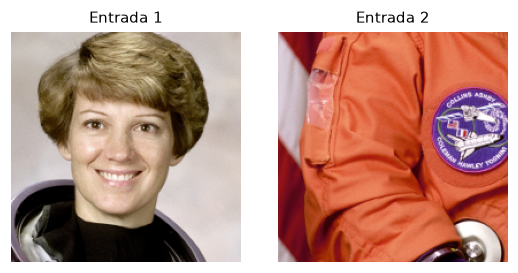

In [9]:
os.makedirs("modelo", exist_ok=True)
joblib.dump(mejor, "modelo/detector_rostro.joblib")
with open("modelo/metadatos.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": mejor_nombre, "clases": CLASES, "semilla": SEMILLA, "entrada": "gris 25×25, valores en [0, 1]",
               "f1_prueba": float(res.loc[res.Alternativa == mejor_nombre, "F1 prueba"].iloc[0])}, f, ensure_ascii=False, indent=2)

modelo_cargado = joblib.load("modelo/detector_rostro.joblib")

def predecir(imagen):
    """Recibe una imagen (RGB o gris, cualquier tamaño, uint8 o float) y devuelve {clase: probabilidad}."""
    im = np.asarray(imagen)
    if im.ndim == 3:
        im = cv2.cvtColor(im.astype(np.uint8) if im.dtype != np.uint8 else im, cv2.COLOR_RGB2GRAY)
    im = util.img_as_float(im)
    im = transform.resize(im, (25, 25), anti_aliasing=True)
    p = modelo_cargado.predict_proba(im[None])[0]
    return {CLASES[i]: float(p[i]) for i in range(len(CLASES))}

astro = data.astronaut()
cara = astro[20:220, 130:330]          # recorte del rostro de la astronauta
print("Recorte de rostro →", predecir(cara))
print("Recorte de fondo  →", predecir(astro[300:500, 0:200]))
mostrar([cara, astro[300:500, 0:200]], ["Entrada 1", "Entrada 2"], tam=2.5)

💬 Observa la **baja confianza** con el rostro de la astronauta: es una imagen de otro *dominio* (a color, de mayor resolución, con otro encuadre). Es la razón por la que la *model card* exige evaluar con fotografías reales del proceso antes de producción.

### Demostración interactiva con Gradio
En Colab, cambia `LANZAR_DEMO = True`: Gradio genera un enlace público temporal que puedes compartir en tu presentación.

In [10]:
LANZAR_DEMO = False
if LANZAR_DEMO:
    # !pip install -q gradio
    import gradio as gr
    demo = gr.Interface(fn=predecir, inputs=gr.Image(type="numpy", label="Fotografía"),
                        outputs=gr.Label(num_top_classes=2, label="Resultado"),
                        title="Validador de fotografía para credencial",
                        description="Prototipo académico. No almacena las imágenes.")
    demo.launch(share=True)
else:
    print("Demo desactivada (LANZAR_DEMO = False).")

Demo desactivada (LANZAR_DEMO = False).


## 7. ¿Y los modelos fundacionales?
Antes de entrenar, pregúntate si un modelo preentrenado ya resuelve tu problema:
| Necesidad | Modelo | Ventaja | Precaución |
|---|---|---|---|
| Clasificar sin datos etiquetados | **CLIP** (zero-shot) | Defines las clases con texto | Sesgos del texto de internet; validar con tus datos |
| Detectar y contar objetos | **YOLO** (Ultralytics) | Tiempo real; ajuste fino sencillo | Licencia AGPL para uso comercial |
| Segmentar a partir de un clic | **SAM** | Pre-etiquetado rápido | Pesado; no sabe *qué* es el objeto |

Ejemplo de clasificación *zero-shot* con CLIP (en Colab; descarga ~600 MB):

In [11]:
USAR_CLIP = False
if USAR_CLIP:
    # !pip install -q transformers
    from transformers import pipeline
    clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32")
    from PIL import Image
    etiquetas = ["una fotografía de un rostro humano", "una fotografía de un paisaje", "una fotografía de un objeto"]
    print(clip(Image.fromarray(cara), candidate_labels=etiquetas))
else:
    print("Ejemplo de CLIP desactivado (USAR_CLIP = False).")

Ejemplo de CLIP desactivado (USAR_CLIP = False).


## 8. Ficha del modelo (*model card*)
La generamos desde el propio cuaderno para que los números siempre coincidan con los resultados.

In [12]:
f1_test = res.loc[res.Alternativa == mejor_nombre, "F1 prueba"].iloc[0]
ic = res.loc[res.Alternativa == mejor_nombre, "IC 95 %"].iloc[0]
tabla_rob = "\n".join(f"| {c} | {v:.3f} |" for c, v in rob.F1.items())
model_card = f"""# Ficha del modelo: Validador de rostro para credenciales

**Versión:** 1.0 · **Fecha:** 2027-04-28 · **Responsable:** Equipo PDI-MCDI

## Uso previsto
Rechazar fotografías **sin rostro** antes de imprimir credenciales. No identifica personas ni verifica identidad.
**Usos fuera de alcance:** reconocimiento facial, vigilancia, inferencia de atributos (edad, género, emociones).

## Modelo
{mejor_nombre}. Entrada: imagen en gris redimensionada a 25×25. Semilla {SEMILLA}.

## Datos
{ficha['Nombre']}: {ficha['Tamaño']}; partición estratificada 70/30.

## Desempeño (conjunto de prueba, n = {len(idx_te)})
F1 = {f1_test:.3f} (IC 95 % bootstrap {ic}).

| Condición | F1 |
|---|---|
{tabla_rob}

## Limitaciones y riesgos éticos
- Entrenado con rostros frontales y centrados de baja resolución; el desempeño con rostros de perfil, con cubrebocas o con iluminación extrema **no ha sido evaluado**.
- Poca diversidad demográfica en los datos: **riesgo de tasas de error desiguales** por tono de piel o edad. Se requiere evaluar por subgrupo antes de producción.
- Las fotografías son datos personales: procesar en memoria y no almacenar (LFPDPPP).

## Recomendaciones
Reentrenar con fotografías reales del proceso (con consentimiento), evaluar por subgrupo y mantener revisión humana de los rechazos.
"""
with open("modelo/MODEL_CARD.md", "w", encoding="utf-8") as f:
    f.write(model_card)
from IPython.display import Markdown
display(Markdown(model_card))

# Ficha del modelo: Validador de rostro para credenciales

**Versión:** 1.0 · **Fecha:** 2027-04-28 · **Responsable:** Equipo PDI-MCDI

## Uso previsto
Rechazar fotografías **sin rostro** antes de imprimir credenciales. No identifica personas ni verifica identidad.
**Usos fuera de alcance:** reconocimiento facial, vigilancia, inferencia de atributos (edad, género, emociones).

## Modelo
B. HOG + SVM. Entrada: imagen en gris redimensionada a 25×25. Semilla 2027.

## Datos
lfw_subset (scikit-image): 200 imágenes en escala de grises de 25×25 px; partición estratificada 70/30.

## Desempeño (conjunto de prueba, n = 60)
F1 = 1.000 (IC 95 % bootstrap [1.00, 1.00]).

| Condición | F1 |
|---|---|
| Original | 1.000 |
| Oscura (×0.5) | 1.000 |
| Ruido σ=0.1 | 0.882 |
| Desenfoque σ=1 | 0.846 |
| Rotación 15° | 0.983 |
| Volteo horizontal | 0.909 |

## Limitaciones y riesgos éticos
- Entrenado con rostros frontales y centrados de baja resolución; el desempeño con rostros de perfil, con cubrebocas o con iluminación extrema **no ha sido evaluado**.
- Poca diversidad demográfica en los datos: **riesgo de tasas de error desiguales** por tono de piel o edad. Se requiere evaluar por subgrupo antes de producción.
- Las fotografías son datos personales: procesar en memoria y no almacenar (LFPDPPP).

## Recomendaciones
Reentrenar con fotografías reales del proceso (con consentimiento), evaluar por subgrupo y mantener revisión humana de los rechazos.


### Dependencias reproducibles

In [13]:
import sklearn
reqs = f"""numpy=={np.__version__}
opencv-python-headless=={cv2.__version__}
scikit-image=={skimage.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""
with open("modelo/requirements.txt", "w") as f:
    f.write(reqs)
print(reqs)
print("Archivos del entregable:", sorted(os.listdir("modelo")))

numpy==2.5.4
opencv-python-headless==5.0.0
scikit-image==0.26.0
scikit-learn==1.9.1
joblib==1.6.0

Archivos del entregable: ['MODEL_CARD.md', 'detector_rostro.joblib', 'metadatos.json', 'requirements.txt']


## 9. Cómo comunicar tus resultados en la sección de discusión
1. **El problema en una frase** y por qué importa (costo, tiempo, riesgo).
2. **Los datos:** de dónde vienen, cuántos son y sus limitaciones.
3. **La solución en un diagrama:** imagen → preprocesamiento → representación → modelo → decisión.
4. **El resultado frente a la meta:** una cifra con su intervalo y una matriz de confusión.
5. **Un error que te enseñó algo** (con imagen).
6. **Limitaciones y siguiente paso:** qué necesitas para llevarlo a producción.

## 10. Lista de verificación de la actividad 5A (30 puntos)
- [ ] Definición del problema y descripción del conjunto de datos. (6)
- [ ] Diseño e implementación del flujo (preprocesamiento, segmentación opcional, extracción de características). (8)
- [ ] Implementación y evaluación del modelo de aprendizaje automático (Pipeline, validación cruzada, matriz de confusión y F1). (8)
- [ ] Claridad en el análisis de resultados, conclusiones y documentación. (8)

**Entrega:** domingo 16 de mayo de 2027, en formato `.ipynb` y `.pdf`.